
## 1. Contexto y Objetivo
El objetivo de este notebook es construir y comparar modelos de Machine Learning supervisados para predecir si un siniestro vial resultará en **Gravedad** (lesionados o fallecidos) o **Solo Daños**.

### Estrategia de Evaluación
Se implementa un **Split Temporal Out-of-Time**:
- **Entrenamiento:** Siniestros ocurridos entre 2016 y 2021.
- **Evaluación (Test):** Siniestros ocurridos en el año 2022 completo.

In [3]:
import numpy as np
import pandas as pd

from tensorflow import keras
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.base import clone
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, roc_auc_score, confusion_matrix)
from sklearn.pipeline import make_pipeline

In [4]:
ruta = r'C:\Users\santa\Desktop\Cositas de Python\UNI\IA\proyectoIA\data\clean\siniestralidad_clean.csv'
df = pd.read_csv(ruta)

C:\Users\santa\AppData\Local\Temp\ipykernel_9404\3138773940.py:2: DtypeWarning: Columns (0: codigo, 1: medio_reporte, 2: direccion_original, 3: direccion_norm) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


In [5]:
df.head(5)

,codigo,fecha,anio,mes,dia_semana_num,dia_semana,es_fin_semana,es_festivo,severidad,fallecido_foraneo,...,veh_motocarro,veh_automovil,veh_camioneta_campero,veh_bus,veh_carga_pesada,veh_bicicleta,direccion_original,direccion_norm,direccion_valida,direccion_con_corrupcion
0,96159,2016-01-01,2016,1,4,viernes,False,True,Solo daños,False,...,False,False,False,False,False,False,Carrera 56 Con Calle 1 A,CARRERA 56 CON CALLE 1 A,True,False
1,96161,2016-01-01,2016,1,4,viernes,False,True,Con lesionado,False,...,False,False,False,False,False,False,Carrera 94 Con Calle 4 C,CARRERA 94 CON CALLE 4 C,True,False
2,96162,2016-01-01,2016,1,4,viernes,False,True,Con lesionado,False,...,False,False,False,False,False,False,Carrera 8 A Con Calle 44,CARRERA 8 A CON CALLE 44,True,False
3,96164,2016-01-01,2016,1,4,viernes,False,True,Solo daños,False,...,False,True,False,False,False,False,Carrera 46 C Con Calle 36,CARRERA 46 C CON CALLE 36,True,False
4,96167,2016-01-01,2016,1,4,viernes,False,True,Con lesionado,False,...,NaN,NaN,NaN,NaN,NaN,NaN,Carrera 23 Con Transversal 25,CARRERA 23 CON TRANSVERSAL 25,True,False


1. Carga, Limpieza y Feature Engineering

In [6]:
# 1. Creación de Target Binario (1 = Grave, 0 = Solo daños)
df['grave'] = (~df['severidad'].isin(['Solo daños'])).astype(int)

# 2. Tratamiento de variables de Vehículos y manejo consciente de NaN
veh_cols = [c for c in df.columns if c.startswith('veh_')]
df['veh_sin_dato'] = df[veh_cols].isna().any(axis=1).astype(int)
for col in veh_cols:
  df[col] = df[col].fillna(False).astype(int)

# 3. Formato de booleanos
df['es_fin_semana'] = df['es_fin_semana'].astype(int)
df['es_festivo'] = df['es_festivo'].astype(int)

# 4. Transformaciones Temporales (Cíclica para Mes + One-Hot para Día)
df['mes_sin'] = np.sin(2 * np.pi * df['mes'] / 12)
df['mes_cos'] = np.cos(2 * np.pi * df['mes'] / 12)
df = pd.get_dummies(
    df, columns=['dia_semana'], prefix='dia', drop_first=True, dtype=int
)

# 5. Selección de Matriz de Características (X) y Target (y)
feature_cols = (
    ['anio', 'mes_sin', 'mes_cos', 'es_fin_semana', 'es_festivo', 'veh_sin_dato', 'num_vehiculos']
    + veh_cols
    + [c for c in df.columns if c.startswith('dia_')]
)

X = df[feature_cols]
y = df['grave']

print(f'Total registros: {X.shape[0]} | Número de predictores: {X.shape[1]}')

Total registros: 124889 | Número de predictores: 21


In [7]:
balanceo = df['grave'].value_counts()
print(balanceo)

grave
0    74029
1    50860
Name: count, dtype: int64


In [8]:
print(X.dtypes.value_counts())
print('\nColumnas no numéricas ni bool:',
      X.select_dtypes(exclude=['number', 'bool']).columns.tolist())
print('\nNaN por columna:')
print(X.isna().sum()[lambda s: s > 0])
print('\nInf:', np.isinf(X.select_dtypes('number')).sum().sum())
print('Valores de y:', np.unique(y, return_counts=True))

int64      18
float64     3
Name: count, dtype: int64

Columnas no numéricas ni bool: []

NaN por columna:
num_vehiculos    5404
dtype: int64

Inf: 0
Valores de y: (array([0, 1]), array([74029, 50860]))


In [9]:
mask_ok = X['num_vehiculos'].notna()
X, y, df = X[mask_ok], y[mask_ok], df[mask_ok]

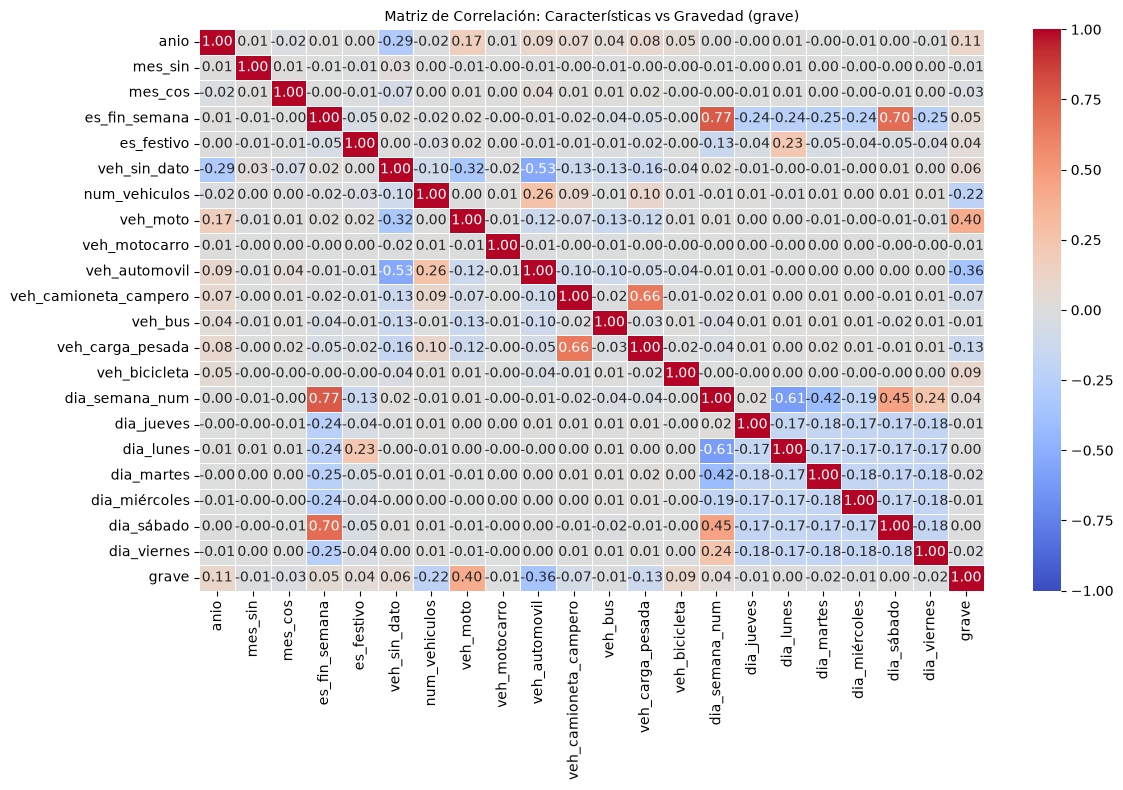

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Combinar características (X) y target (y) en un único DataFrame para calcular la correlación
df_corr = X.copy()
df_corr['grave'] = y

# Calcular la matriz de correlación de Pearson
corr_matrix = df_corr.corr()

# Configurar el lienzo de visualización
plt.figure(figsize=(12, 8))

# Dibujar el mapa de calor (Heatmap)
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Matriz de Correlación: Características vs Gravedad (grave)', fontsize=10)
plt.tight_layout()
plt.show()

2. Split Temporal y Escalado

In [11]:
mask_train = df['anio'] < 2022
mask_test = df['anio'] == 2022

X_tr_raw, y_tr = X[mask_train], y[mask_train]
X_te_raw, y_te = X[mask_test], y[mask_test]

# Normalizacion
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(
    f'Entrenamiento (2016-2021): {X_tr.shape[0]} registros | % Graves:'
    f' {y_tr.mean():.1%}'
)
print(
    f'Evaluación Test (2022): {X_te.shape[0]} registros | % Graves:'
    f' {y_te.mean():.1%}'
)

print(y_tr.shape)

Entrenamiento (2016-2021): 101188 registros | % Graves: 37.6%
Evaluación Test (2022): 9817 registros | % Graves: 44.9%
(101188,)


In [12]:
print('NaN en X_tr:', np.isnan(X_tr).sum(), '| NaN en X_te:', np.isnan(X_te).sum())

NaN en X_tr: 0 | NaN en X_te: 0


3. Entrenamiento y Evaluación

In [18]:
model = keras.models.Sequential([
    #keras.layers.Dense(units=64, activation='relu', input_shape=(X_tr.shape[1],)),
    #keras.layers.Dropout(0.2),
    keras.layers.Dense(units=32, activation='relu', input_shape=(X_tr.shape[1],)),
    #keras.layers.Dropout(0.2),
    keras.layers.Dense(units=16, activation='relu'),
    keras.layers.Dense(units=1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

C:\Users\santa\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,249 (4.88 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(X_tr, y_tr, epochs=30, validation_data=(X_te, y_te), verbose=1, batch_size=256)

Epoch 1/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7387 - loss: 0.5248 - val_accuracy: 0.6960 - val_loss: 0.5736
Epoch 2/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7631 - loss: 0.4819 - val_accuracy: 0.7190 - val_loss: 0.5444
Epoch 3/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7664 - loss: 0.4782 - val_accuracy: 0.7397 - val_loss: 0.5323
Epoch 4/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7700 - loss: 0.4761 - val_accuracy: 0.7549 - val_loss: 0.5265
Epoch 5/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7705 - loss: 0.4749 - val_accuracy: 0.7452 - val_loss: 0.5295
Epoch 6/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7723 - loss: 0.4744 - val_accuracy: 0.7553 - val_loss: 0.5231
Epoch 7/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7720 - loss: 0.4739 - val_accuracy: 0.7560 - val_loss: 0.5257
Epoch 8/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7722 - loss: 0.4733 - val_accuracy: 0.

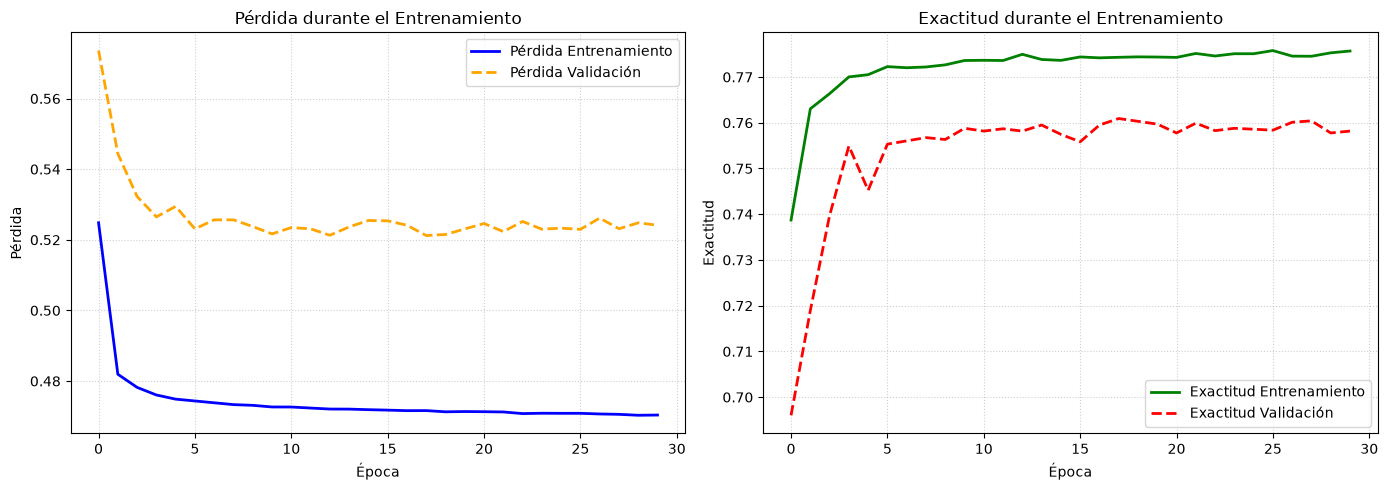

In [20]:
import matplotlib.pyplot as plt

# Configurar el lienzo para dos subgráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Gráfica de Pérdida (Loss)
ax1.plot(history.history['loss'], label='Pérdida Entrenamiento', color='blue', linewidth=2)
if 'val_loss' in history.history:
    ax1.plot(history.history['val_loss'], label='Pérdida Validación', color='orange', linestyle='--', linewidth=2)
ax1.set_title('Pérdida durante el Entrenamiento', fontsize=12)
ax1.set_xlabel('Época', fontsize=10)
ax1.set_ylabel('Pérdida', fontsize=10)
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# 2. Gráfica de Exactitud (Accuracy)
ax2.plot(history.history['accuracy'], label='Exactitud Entrenamiento', color='green', linewidth=2)
if 'val_accuracy' in history.history:
    ax2.plot(history.history['val_accuracy'], label='Exactitud Validación', color='red', linestyle='--', linewidth=2)
ax2.set_title('Exactitud durante el Entrenamiento', fontsize=12)
ax2.set_xlabel('Época', fontsize=10)
ax2.set_ylabel('Exactitud', fontsize=10)
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

3163/3163 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step
307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

--- Métricas para el Conjunto de Entrenamiento ---
Informe de Clasificación (Entrenamiento):
               precision    recall  f1-score   support

           0       0.79      0.87      0.83     63104
           1       0.74      0.62      0.68     38084

    accuracy                           0.78    101188
   macro avg       0.77      0.74      0.75    101188
weighted avg       0.77      0.78      0.77    101188



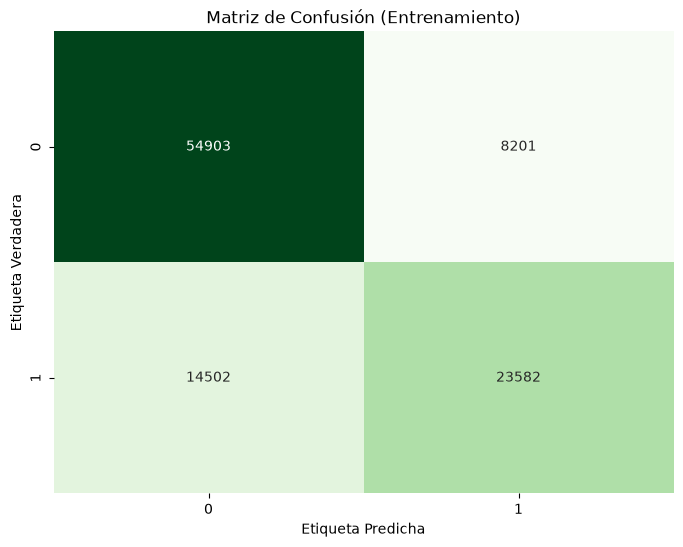


--- Métricas para el Conjunto de Prueba ---
Informe de Clasificación (Prueba):
               precision    recall  f1-score   support

           0       0.82      0.72      0.77      5408
           1       0.70      0.80      0.75      4409

    accuracy                           0.76      9817
   macro avg       0.76      0.76      0.76      9817
weighted avg       0.77      0.76      0.76      9817



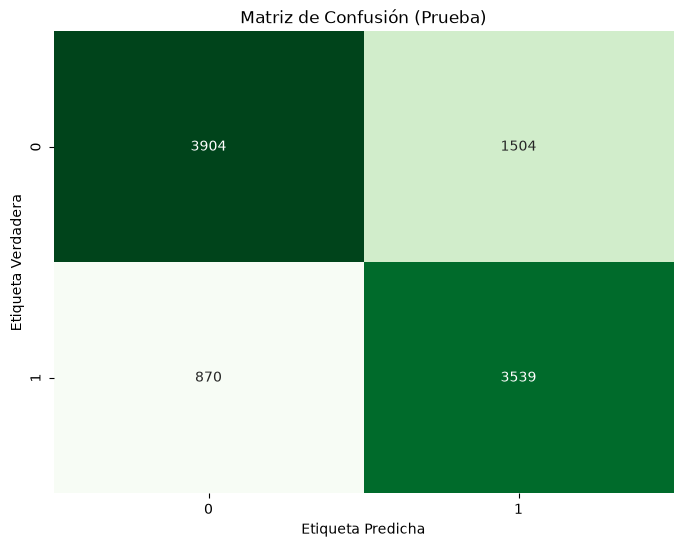

In [21]:
# Obtener predicciones del modelo para el conjunto de entrenamiento y prueba
# (una sola salida sigmoide: probabilidad de grave y clase con umbral 0.5)
y_pred_train = model.predict(X_tr).ravel()
y_pred_train_classes = (y_pred_train >= 0.5).astype(int)

y_pred_test = model.predict(X_te).ravel()
y_pred_test_classes = (y_pred_test >= 0.5).astype(int)

# Obtener las clases únicas de la variable objetivo para las etiquetas del heatmap
class_labels = np.unique(y_tr)

print("\n--- Métricas para el Conjunto de Entrenamiento ---")
print("Informe de Clasificación (Entrenamiento):\n", classification_report(y_tr, y_pred_train_classes))
cm_train = confusion_matrix(y_tr, y_pred_train_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_train, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Matriz de Confusión (Entrenamiento)')
plt.ylabel('Etiqueta Verdadera')
plt.xlabel('Etiqueta Predicha')
plt.show()

print("\n--- Métricas para el Conjunto de Prueba ---")
print("Informe de Clasificación (Prueba):\n", classification_report(y_te, y_pred_test_classes))
cm_test = confusion_matrix(y_te, y_pred_test_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Greens", cbar=False,
            xticklabels=class_labels, yticklabels=class_labels)
plt.title('Matriz de Confusión (Prueba)')
plt.ylabel('Etiqueta Verdadera')
plt.xlabel('Etiqueta Predicha')
plt.show()

## Conclusion

La MLP tiene un buen desemepeño en general, el desbalance de clases levemente en la clase 0 o categoria solo daños genera un pequeño overfitting en el modelo, implementar drop out es opcional, si aumentan los datos

- En el entrenamiento el modelo tiene una perdida ideal estabilizandose con las epocas

- La exactitud del modelo es buena aumentando con las epocas tanto para el entrenamiento con para la validacion


## En la matriz de confusion y el reporte de clasificacion podemos recalcar los siguiente:

- El modelo tiene un accuracy alta tanto para el entrenamiento como para la validacion, sin embargo, en la vida real, los datasets de accidentes de tránsito están desbalanceados, la gran mayoría de los accidentes son leves y solo un porcentaje menor son graves.

- La metrica recall para el entrenamiento es un poco baja y en un modelo que clasifica emergencias o casos de vida o muerte es muy importante esta metrica recall ya que esta nos indica para nuestro contexto, que porcentaje de accidente graves fue capaz de detectar el modelo. Esto es importante porque es preferible que el modelo prediga que un accidente fue grave cuando no fue asi a que prediga que un accidente fue leve cuando fue todo lo contrario

- En machine learning, si las métricas de prueba son muy similares (o incluso ligeramente mejores en algunas clases, como pasó aquí con el F1-score de la clase 1 que subió de 0.67 a 0.74), significa que no está memorizando los datos, sino que aprendió patrones reales que aplican a datos nuevos que nunca antes había visto.



In [17]:
import os, json, joblib, sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

veh_cols = [c for c in df.columns if c.startswith('veh_') and c != 'veh_sin_dato']
tr, te = df['anio'] <= 2020, df['anio'] == 2022

mlp = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
mlp.fit(df.loc[tr, veh_cols].astype(int), df.loc[tr, 'grave'])
auc = roc_auc_score(df.loc[te, 'grave'], mlp.predict_proba(df.loc[te, veh_cols].astype(int))[:, 1])
print(f'ROC-AUC solo vehículos (test 2022): {auc:.3f}')
print('Versión de scikit-learn:', sklearn.__version__) 

os.makedirs('demo_siniestros/modelo', exist_ok=True)
os.makedirs('demo_siniestros/datos', exist_ok=True)
joblib.dump(mlp, 'demo_siniestros/modelo/mlp_vehiculos.joblib')
json.dump(veh_cols, open('demo_siniestros/modelo/columnas.json', 'w'))

# % histórico de graves por combinación de vehículos (2016-2022)
(df[df['anio'] <= 2022]
   .groupby(veh_cols)['grave'].agg(n='size', pct_grave='mean')
   .reset_index().to_csv('demo_siniestros/datos/tasa_combinaciones.csv', index=False))

ROC-AUC solo vehículos (test 2022): 0.796
Versión de scikit-learn: 1.9.0
